In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv("/content/train_Eletric_Vehicle.csv")
df.head()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  object 
 9   City_Type                    668665 non-null  object 
 10  Current_Car_Type             668665 non-null  object 
 11  Home_Charging_Possible       668665 non-null  object 
 12  Subsidy_Available            668665 non-null  object 
 13 

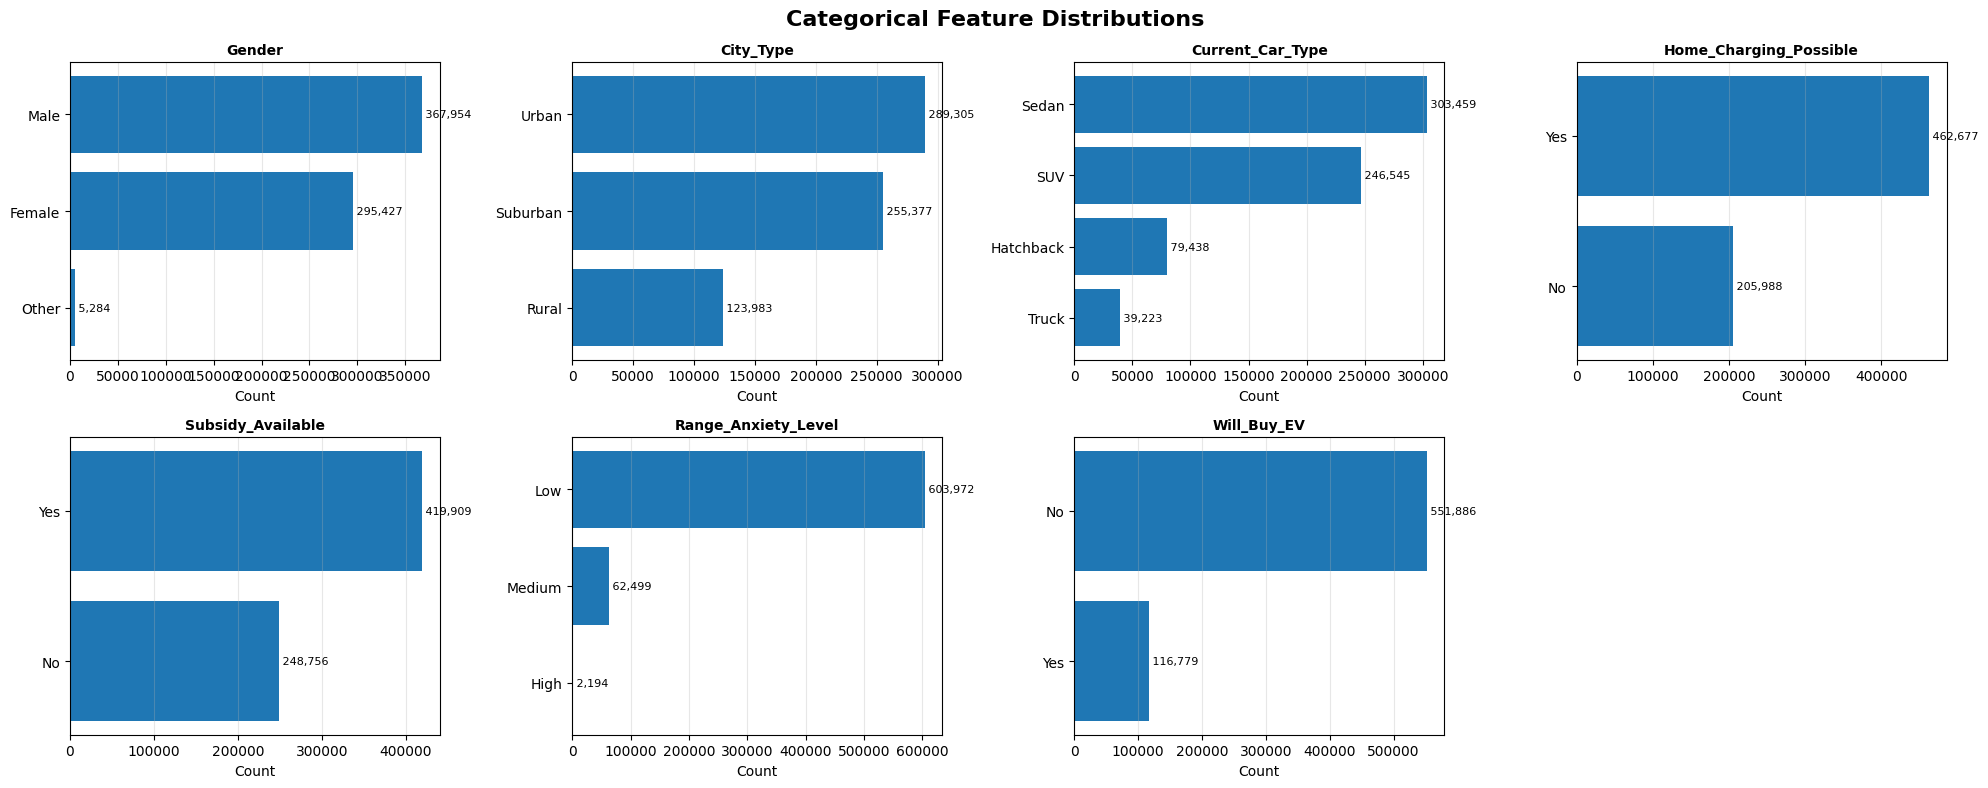

In [ ]:
# @title
def plot_distributions(df, top_n=10, max_unique_numeric=10, n_cols=4):

    categorical_cols = []

    for col in df.columns:

        # categórica tradicional
        if (
            df[col].dtype == "object"
            or str(df[col].dtype) == "category"
            or df[col].dtype == "bool"
        ):
            categorical_cols.append(col)

        # numérica com poucos valores únicos
        elif df[col].nunique() <= max_unique_numeric:
            categorical_cols.append(col)

    n_features = len(categorical_cols)
    n_rows = math.ceil(n_features / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(5 * n_cols, 4 * n_rows)
    )

    axes = axes.flatten()

    for i, col in enumerate(categorical_cols):

        counts = (
            df[col]
            .fillna("Missing")
            .astype(str)
            .value_counts()
            .head(top_n)
            .sort_values()
        )

        axes[i].barh(counts.index, counts.values)

        axes[i].set_title(
            col,
            fontweight="bold",
            fontsize=10
        )

        axes[i].set_xlabel("Count")
        axes[i].grid(axis="x", alpha=0.3)

        for j, value in enumerate(counts.values):
            axes[i].text(
                value,
                j,
                f" {value:,}",
                va="center",
                fontsize=8
            )

    for j in range(n_features, len(axes)):
        fig.delaxes(axes[j])

    fig.suptitle(
        "Categorical Feature Distributions",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

plot_categorical_distributions(df, top_n=10)

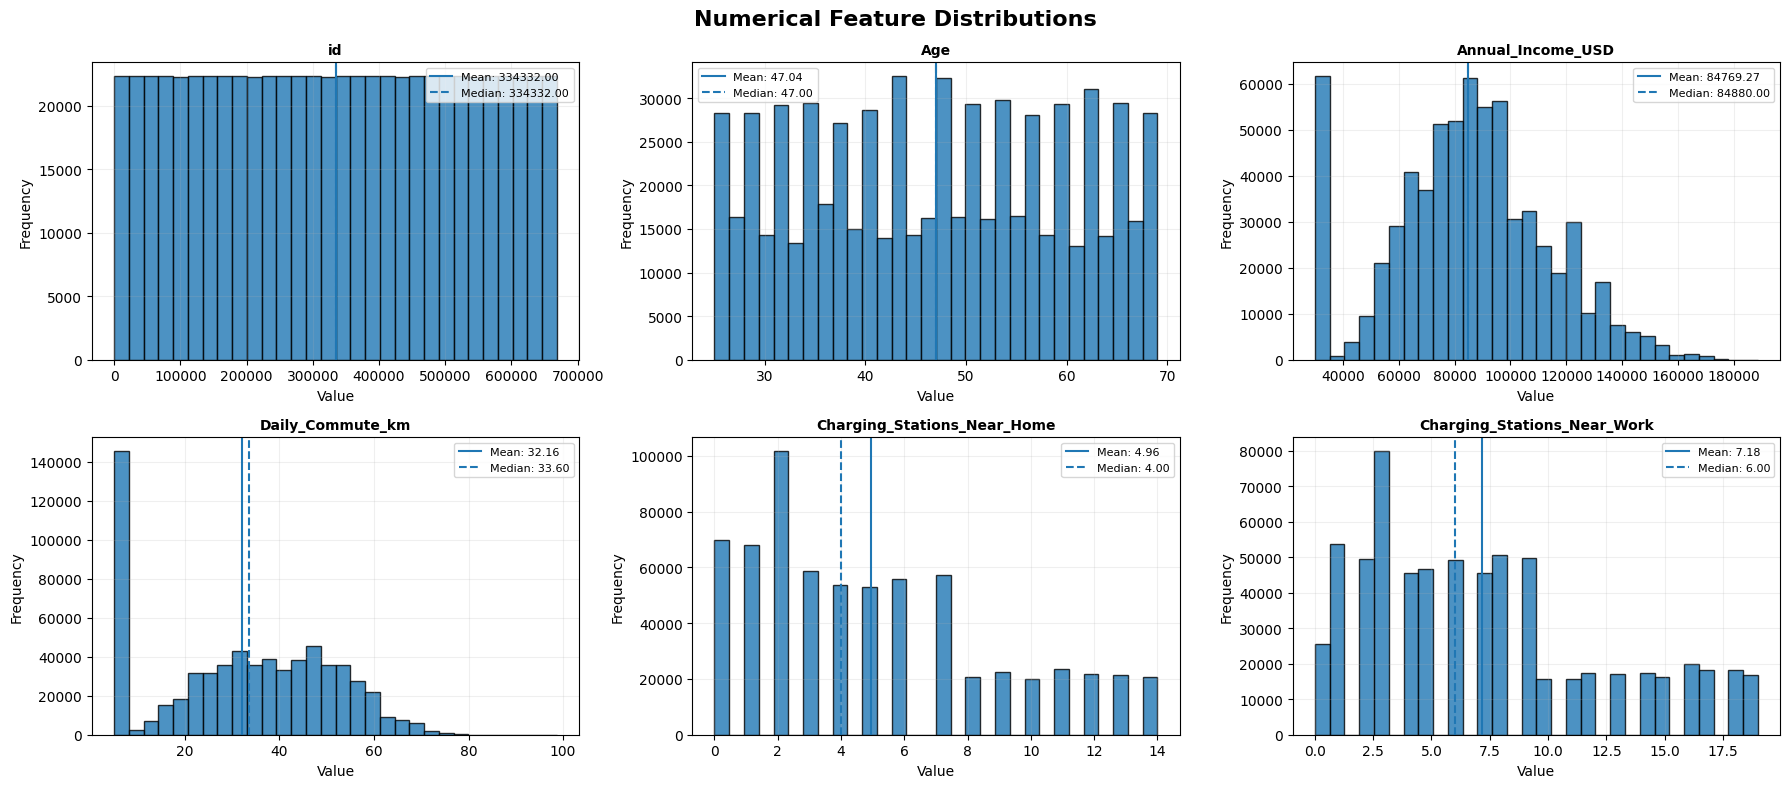

In [ ]:
# @title
import matplotlib.pyplot as plt
import numpy as np
import math


def plot_numerical_distributions(
    df,
    n_cols=3,
    bins=30,
    min_unique=10
):

    # Seleciona apenas numéricas que tenham mais de X valores únicos
    # Isso evita tratar variáveis categóricas numéricas como contínuas
    num_cols = [
        col for col in df.select_dtypes(include="number").columns
        if df[col].nunique() > min_unique
    ]

    n_features = len(num_cols)
    n_rows = math.ceil(n_features / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(6 * n_cols, 4 * n_rows)
    )

    # Garante que axes sempre seja iterável
    axes = np.array(axes).reshape(-1)

    for i, col in enumerate(num_cols):

        data = df[col].dropna()

        mean = data.mean()
        median = data.median()

        # Histograma
        axes[i].hist(
            data,
            bins=bins,
            alpha=0.8,
            edgecolor="black"
        )

        # Média
        axes[i].axvline(
            mean,
            linestyle="-",
            linewidth=1.5,
            label=f"Mean: {mean:.2f}"
        )

        # Mediana
        axes[i].axvline(
            median,
            linestyle="--",
            linewidth=1.5,
            label=f"Median: {median:.2f}"
        )

        axes[i].set_title(
            col,
            fontsize=10,
            fontweight="bold"
        )

        axes[i].set_xlabel("Value")
        axes[i].set_ylabel("Frequency")
        axes[i].grid(alpha=0.2)

        axes[i].legend(fontsize=8)

    # Remove espaços/gráficos vazios
    for j in range(n_features, len(axes)):
        fig.delaxes(axes[j])

    fig.suptitle(
        "Numerical Feature Distributions",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

plot_numerical_distributions(df)

In [ ]:
df["Daily_Commute_km"].quantile(
    [0, .1, .2, .3, .4, .5, .6, .7, .8, .9, 1]
)

,Daily_Commute_km
0.0,5.0
0.1,5.0
0.2,5.0
0.3,21.9
0.4,28.3
0.5,33.6
0.6,39.0
0.7,44.9
0.8,49.8
0.9,55.8


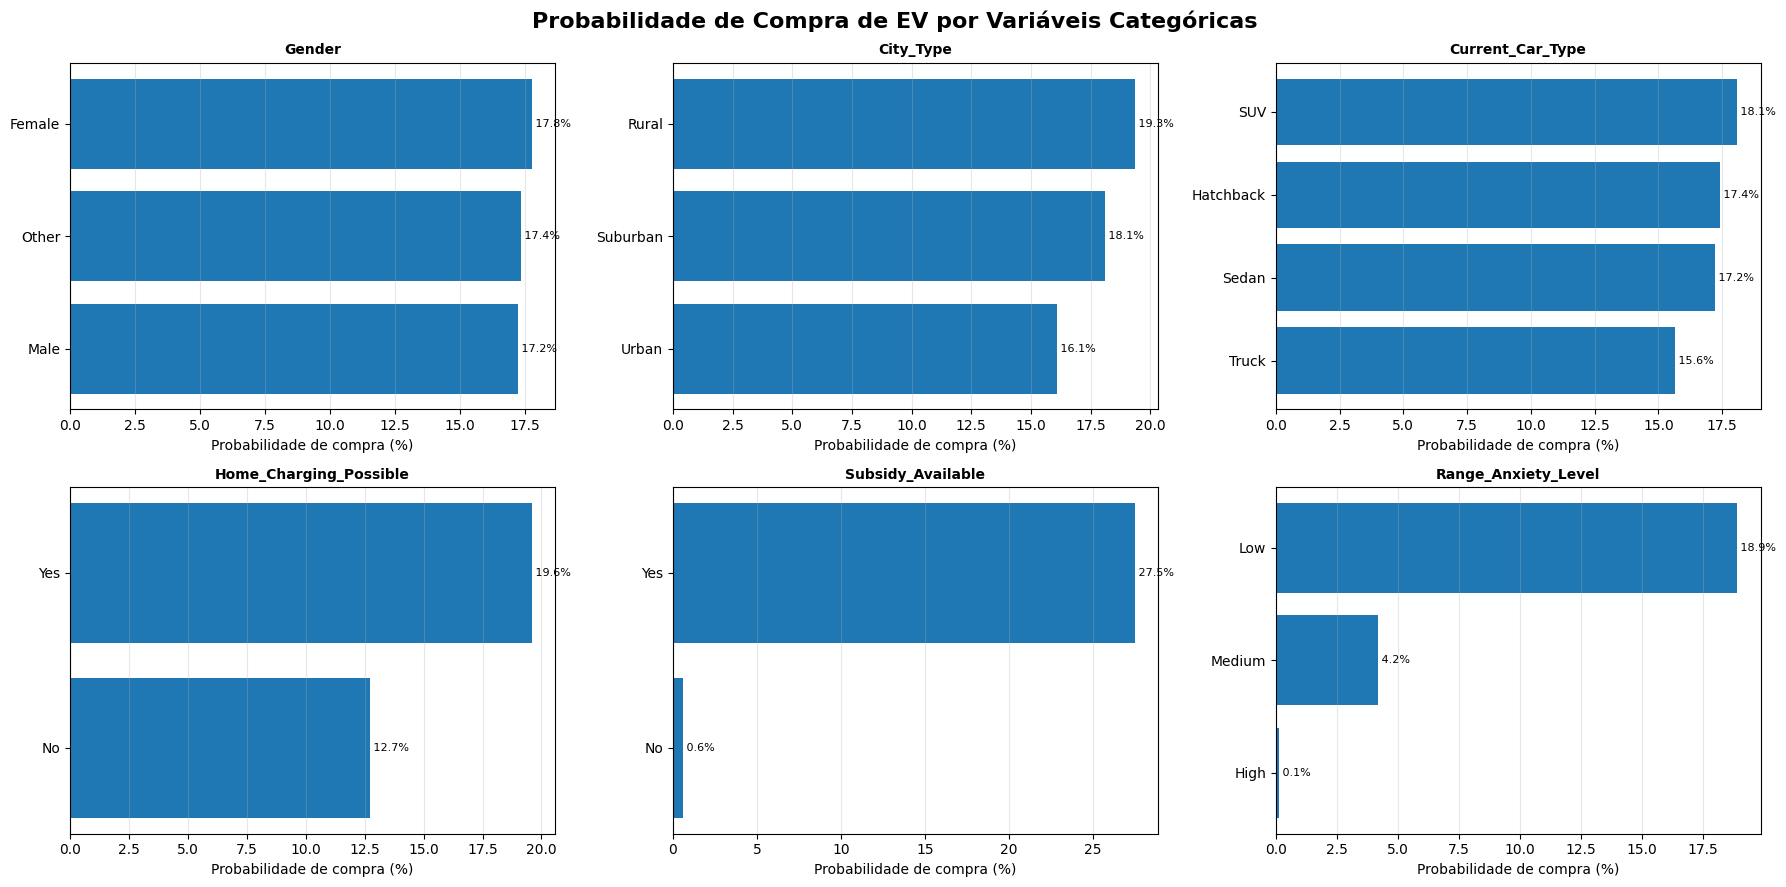

In [ ]:
# @title
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math


# Mantém essa conversão
df["Will_Buy_EV_num"] = (
    df["Will_Buy_EV"]
    .map({"No": 0, "Yes": 1})
)


def plot_prob_compra_categoricas(
    df,
    target="Will_Buy_EV_num",
    n_cols=3,
    top_n=10
):

    # Seleciona colunas categóricas
    cat_cols = [
        col
        for col in df.select_dtypes(
            include=["object", "category", "bool"]
        ).columns
        if col != "Will_Buy_EV"
    ]

    resultados = {}

    n_features = len(cat_cols)
    n_rows = math.ceil(n_features / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(6 * n_cols, 4.5 * n_rows)
    )

    axes = np.array(axes).reshape(-1)

    for i, col in enumerate(cat_cols):

        temp = df[[col, target]].copy()

        # Trata nulos como categoria
        temp[col] = temp[col].fillna("Missing")

        # Estatísticas por categoria
        resumo = (
            temp
            .groupby(col, observed=True)
            .agg(
                qtd=(target, "size"),
                prob_compra=(target, "mean")
            )
            .reset_index()
        )

        resumo["prob_compra"] *= 100

        # Se houver muitas categorias,
        # mantém as mais frequentes
        if len(resumo) > top_n:
            resumo = (
                resumo
                .sort_values("qtd", ascending=False)
                .head(top_n)
            )

        # Ordena pela probabilidade
        resumo = resumo.sort_values(
            "prob_compra",
            ascending=True
        )

        resultados[col] = resumo.copy()

        # -------------------------
        # Gráfico
        # -------------------------

        ax = axes[i]

        bars = ax.barh(
            resumo[col].astype(str),
            resumo["prob_compra"]
        )

        ax.set_title(
            col,
            fontsize=10,
            fontweight="bold"
        )

        ax.set_xlabel(
            "Probabilidade de compra (%)"
        )

        ax.set_ylabel("")

        ax.grid(
            axis="x",
            alpha=0.3
        )

        # Probabilidade no final da barra
        for bar, prob in zip(
            bars,
            resumo["prob_compra"]
        ):

            ax.text(
                bar.get_width(),
                bar.get_y() + bar.get_height() / 2,
                f" {prob:.1f}%",
                va="center",
                fontsize=8
            )

    # Remove gráficos vazios
    for j in range(n_features, len(axes)):
        fig.delaxes(axes[j])

    fig.suptitle(
        "Probabilidade de Compra de EV por Variáveis Categóricas",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

    return resultados

resultados_cat = plot_prob_compra_categoricas(df)

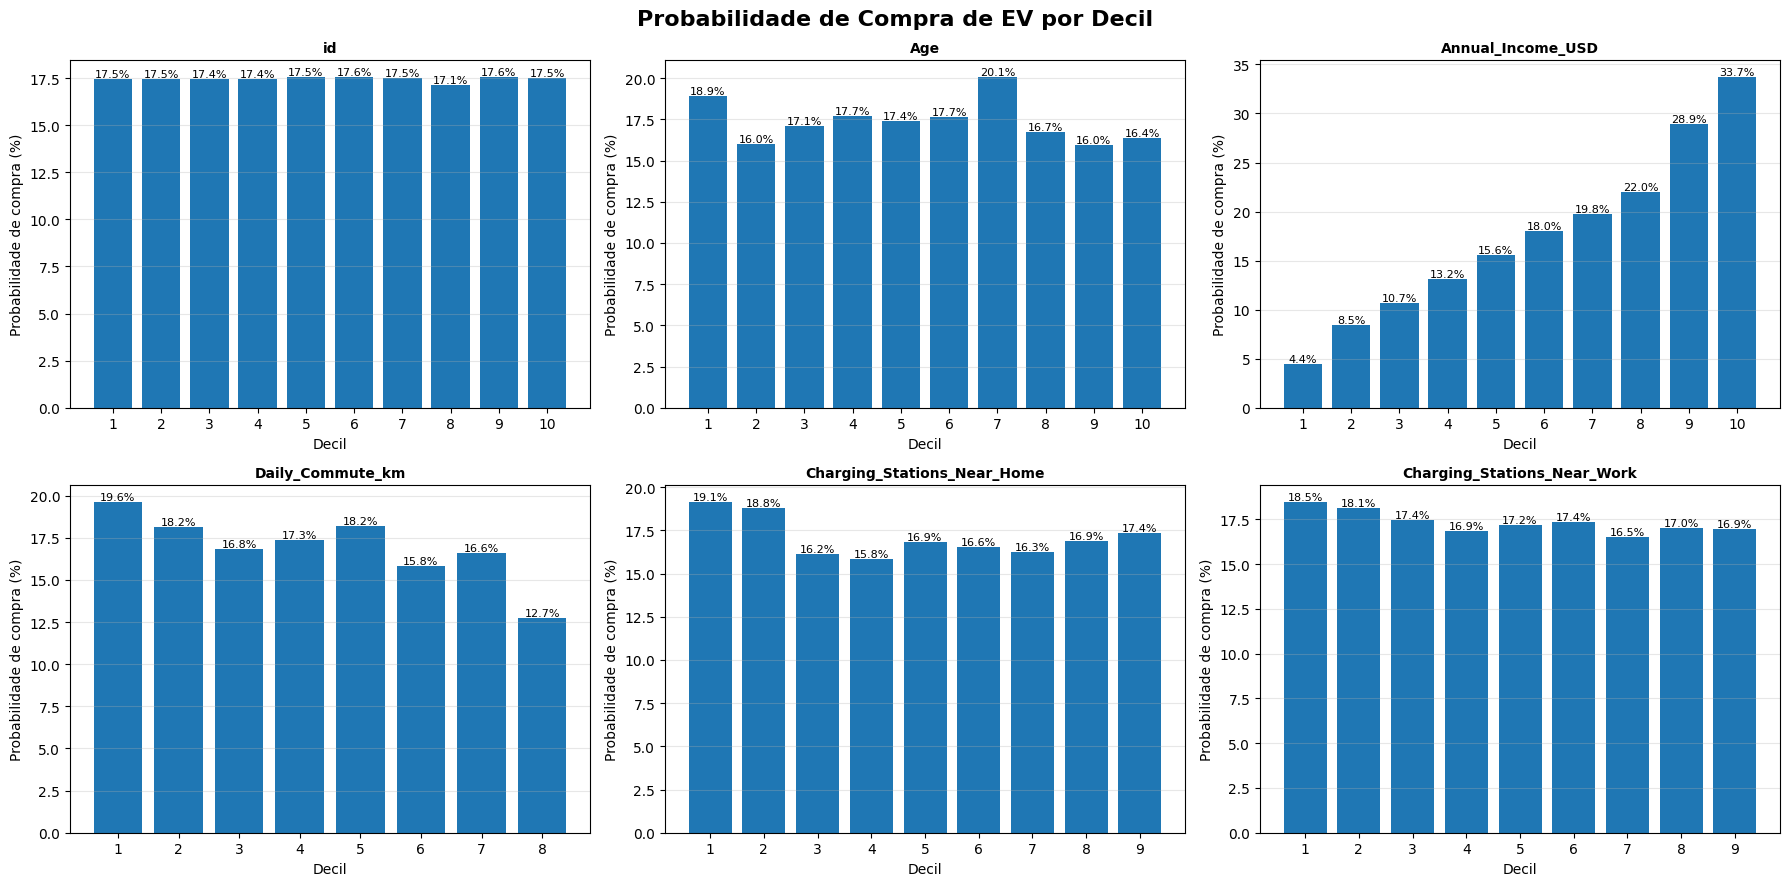

In [ ]:
# @title
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math


def plot_prob_compra_por_decil(
    df,
    target="Will_Buy_EV",
    positive_class="Yes",
    n_cols=3,
    min_unique=10,
    force_10_deciles=False
):

    # Seleciona colunas numéricas
    num_cols = [
        col
        for col in df.select_dtypes(include=np.number).columns
        if col != target
        and df[col].nunique() > min_unique
    ]

    resultados = {}

    n_features = len(num_cols)
    n_rows = math.ceil(n_features / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(6 * n_cols, 4.5 * n_rows)
    )

    axes = np.array(axes).reshape(-1)

    for i, col in enumerate(num_cols):

        # Mantém apenas registros válidos
        temp = df[[col, target]].dropna().copy()

        # Target: Yes = 1 / restante = 0
        temp["target_num"] = (
            temp[target]
            .eq(positive_class)
            .astype(int)
        )

        # --------------------------------
        # Criação dos decis
        # --------------------------------

        if force_10_deciles:
            # Força aproximadamente 10% da população
            # em cada decil, mesmo havendo valores repetidos
            ranking = temp[col].rank(method="first")

            temp["decil"] = (
                pd.qcut(
                    ranking,
                    q=10,
                    labels=False
                ) + 1
            )

        else:
            # Mantém valores iguais no mesmo grupo.
            # Pode gerar menos de 10 decis caso existam
            # muitos valores repetidos.
            temp["decil"] = (
                pd.qcut(
                    temp[col],
                    q=10,
                    labels=False,
                    duplicates="drop"
                ) + 1
            )

        # --------------------------------
        # Estatísticas por decil
        # --------------------------------

        resumo = (
            temp
            .groupby("decil", observed=True)
            .agg(
                min_valor=(col, "min"),
                max_valor=(col, "max"),
                qtd=(target, "size"),
                prob_compra=("target_num", "mean")
            )
            .reset_index()
        )

        resumo["prob_compra"] *= 100

        resultados[col] = resumo

        # --------------------------------
        # Gráfico
        # --------------------------------

        ax = axes[i]

        bars = ax.bar(
            resumo["decil"],
            resumo["prob_compra"]
        )

        ax.set_title(
            col,
            fontsize=10,
            fontweight="bold"
        )

        ax.set_xlabel("Decil")
        ax.set_ylabel("Probabilidade de compra (%)")

        ax.set_xticks(resumo["decil"])

        ax.grid(
            axis="y",
            alpha=0.3
        )

        # Valores em cima das barras
        for bar, prob in zip(bars, resumo["prob_compra"]):

            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height(),
                f"{prob:.1f}%",
                ha="center",
                va="bottom",
                fontsize=8
            )

    # Remove gráficos vazios
    for j in range(n_features, len(axes)):
        fig.delaxes(axes[j])

    fig.suptitle(
        "Probabilidade de Compra de EV por Decil",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

    return resultados

resultados_decis = plot_prob_compra_por_decil(df)

In [ ]:
df['Charging_Stations_Near_Work'].value_counts()

,count
Charging_Stations_Near_Work,
3,79739
1,53736
8,50675
9,49745
2,49538
6,49103
5,46737
7,45594
4,45472


In [ ]:
def preparar_features(df):
    df_clean = df.copy()


    df_clean['Gender'] = df_clean['Gender'].map({
        'Male': 0,
        'Female': 1
    })

    df_clean['Range_Anxiety_Level'] = df_clean['Range_Anxiety_Level'].map({
        'Low': 0,
        'Medium': 1,
        'High': 2
    })

    df_clean['Home_Charging_Possible'] = df_clean['Home_Charging_Possible'].map({
        'Yes': 1,
        'No': 0
    })

    df_clean['Subsidy_Available'] = df_clean['Subsidy_Available'].map({
        'Yes': 1,
        'No': 0
    })

    df_clean['Will_Buy_EV'] = df_clean['Will_Buy_EV'].map({
        'Yes': 1,
        'No': 0
    })


    df["Gender_x_Charging_x_Anxiety"] = (
    df["Gender"].astype(str)
    + "_"
    + df["Home_Charging_Possible"].astype(str)
    + "_"
    + df["Range_Anxiety_Level"].astype(str))


    df["Age_Decil"] = pd.qcut(
    df["Age"],
    q=10,
    labels=False,
    duplicates="drop")

    df["Annual_Income_USD_Decil"] = pd.qcut(
    df["Annual_Income_USD"],
    q=100,
    labels=False,
    duplicates="drop")

    df["Daily_Commute_km_Decil"] = pd.qcut(
    df["Daily_Commute_km"],
    q=10,
    labels=False,
    duplicates="drop")

    for k in [4, 3, 2, 1, 0]:
        df[f"inc_d{k}"] = (
            df["Annual_Income_USD"] // 10**k % 10
        ).astype("int8")




    return df_clean

In [ ]:
num_cols= [
    'Gender',
    'Range_Anxiety_Level',
    'Annual_Income_USD',
    'Daily_Commute_km',
    'Number_of_Cars_Owned',
    'Charging_Stations_Near_Home',
    'Charging_Stations_Near_Work',
    'Environmental_Concern_Level'
]

cat_cols = [
    'City_Type',
    'Current_Car_Type',
    'Gender_x_Charging_x_Anxiety'
]

bool_cols = [
    'Home_Charging_Possible',
    'Subsidy_Available'
]

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

In [ ]:
pipeline_num = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [ ]:
pipeline_cat = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

In [ ]:
pipeline_bool = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

In [ ]:
df_modelo = preparar_features(df)

X = df_modelo.drop(columns=["Will_Buy_EV"])
y = df_modelo["Will_Buy_EV"]

In [ ]:
preprocessador = ColumnTransformer([
    ("num", pipeline_num, num_cols),
    ("cat", pipeline_cat, cat_cols),
    ("bool", pipeline_bool, bool_cols)
])

In [ ]:
print(df_modelo["Will_Buy_EV"].value_counts(dropna=False))
print(df_modelo["Will_Buy_EV"].unique())

Will_Buy_EV
0    551886
1    116779
Name: count, dtype: int64
[0 1]


In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score

df_modelo = preparar_features(df)

X = df_modelo.drop(columns=["Will_Buy_EV"])

y = df_modelo["Will_Buy_EV"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

In [ ]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

pipeline_xgb = Pipeline([
    ("preprocessamento", preprocessador),

    ("modelo", XGBClassifier(
        random_state=42,
        eval_metric="auc",
        tree_method="hist",

        # deixa o paralelismo para o RandomizedSearchCV
        n_jobs=1
    ))
])

param_xgb = {
    "modelo__n_estimators": [300, 500, 700],
    "modelo__learning_rate": [0.03, 0.05, 0.08],
    "modelo__max_depth": [3, 4, 5, 6],
    "modelo__min_child_weight": [1, 3, 5],
    "modelo__subsample": [0.8, 0.9, 1.0],
    "modelo__colsample_bytree": [0.8, 0.9, 1.0],
    "modelo__reg_alpha": [0, 0.1, 1],
    "modelo__reg_lambda": [1, 5, 10]
}

random_xgb = RandomizedSearchCV(
    estimator=pipeline_xgb,
    param_distributions=param_xgb,

    n_iter=10,          # era 40
    scoring="roc_auc",
    cv=cv,              # agora 3 folds

    random_state=42,
    n_jobs=-1,
    verbose=2
)

random_xgb.fit(X_train, y_train)

print(random_xgb.best_params_)
print(random_xgb.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
{'modelo__subsample': 0.9, 'modelo__reg_lambda': 10, 'modelo__reg_alpha': 0, 'modelo__n_estimators': 700, 'modelo__min_child_weight': 5, 'modelo__max_depth': 4, 'modelo__learning_rate': 0.05, 'modelo__colsample_bytree': 1.0}
0.9414474686321889


In [ ]:
pred_xgb = random_xgb.best_estimator_.predict_proba(
    X_test
)[:, 1]

auc_xgb = roc_auc_score(
    y_test,
    pred_xgb
)

print("AUC XGBoost no holdout:", auc_xgb)

AUC XGBoost no holdout: 0.9413441985965791


In [ ]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)